# 1. Data set cleaning

In [1]:
import pandas as pd


In [2]:
# 1. Load the dataset

url="/content/drive/MyDrive/netflix_titles.csv"
df = pd.read_csv(url)

In [3]:
print("--- Original Data Shape ---")
print(df.shape)  # Shows number of rows and columns


--- Original Data Shape ---
(6234, 12)


In [4]:
# 2. check for missing values (nulls)
print("\n---- missing values per column----")
print(df.isnull().sum())


---- missing values per column----
show_id            0
type               0
title              0
director        1969
cast             570
country          476
date_added        11
release_year       0
rating            10
duration           0
listed_in          0
description        0
dtype: int64


In [5]:
# 3. Handle missing values cleanly
# For 'director' and 'cast', replace missing names with 'Unknown'
df["director"]=df["director"].fillna("Unknown")
df["cast"]=df["cast"].fillna("Unknown")

# For 'country', replace missing entries with the most common country (USA)
df["country"]=df["country"].fillna("USA")

# For 'rating', replace missing values with 'UR' (Unrated)
df["rating"]=df["rating"].fillna("UR")


In [6]:
# 4. Fix the date format safely
# Force the column to be read as string first to prevent the .str accessor error
df['date_added'] = df['date_added'].astype(str).str.strip()

# Convert the cleaned text into a standard datetime format automatically
df['date_added'] = pd.to_datetime(df['date_added'], format='mixed', errors='coerce')

In [7]:
# 5. Drop remaining rows with crucial missing data
# If a row is missing the 'duration', we drop just that specific row
df =df.dropna(subset=["duration"])


In [8]:
#  Drop the 11 rows where date_added could not be fixed
df=df.dropna(subset=["date_added"])

In [9]:
# 6. Verify everything is clean
print("\n ----missings values after cleaning----")
print(df.isnull().sum())



 ----missings values after cleaning----
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


In [10]:
# 7. Save your clean dataset to a new file
df.to_csv("netflix_clean_data", index=False )
print("\n  Success clean data is saved as ' netflix_clean_data' ")


  Success clean data is saved as ' netflix_clean_data' 


# 2. Performing EDA on Cleaned dataset

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv("/content/netflix_clean_data")



In [12]:
print(df.columns)

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')


In [13]:
content_count=df['type'].value_counts()
print("\ncontent type split")
print(content_count)

# Percentage breakdown
print("\n percentage breakdown")
print(df['type'].value_counts(normalize= True)*100)


content type split
type
Movie      4264
TV Show    1959
Name: count, dtype: int64

 percentage breakdown
type
Movie      68.520006
TV Show    31.479994
Name: proportion, dtype: float64


In [14]:
# Extract the year from our clean date_added column
df['year_added'] = pd.to_datetime(df['date_added']).dt.year

# Count content added per year
growth_trends = df['year_added'].value_counts().sort_index()
print("\n--- Content Added Per Year ---")
print(growth_trends)



--- Content Added Per Year ---
year_added
2008       2
2009       2
2010       1
2011      13
2012       7
2013      12
2014      25
2015      90
2016     456
2017    1300
2018    1782
2019    2349
2020     184
Name: count, dtype: int64


In [15]:
# Split genres separated by commas and count them individually
all_genres = df['listed_in'].str.split(', ').explode()
top_genres = all_genres.value_counts().head(5)

print("\n--- Top 5 Genres on Netflix ---")
print(top_genres)



--- Top 5 Genres on Netflix ---
listed_in
International Movies      1927
Dramas                    1623
Comedies                  1113
International TV Shows    1000
Documentaries              668
Name: count, dtype: int64


# 3. Data Visualization

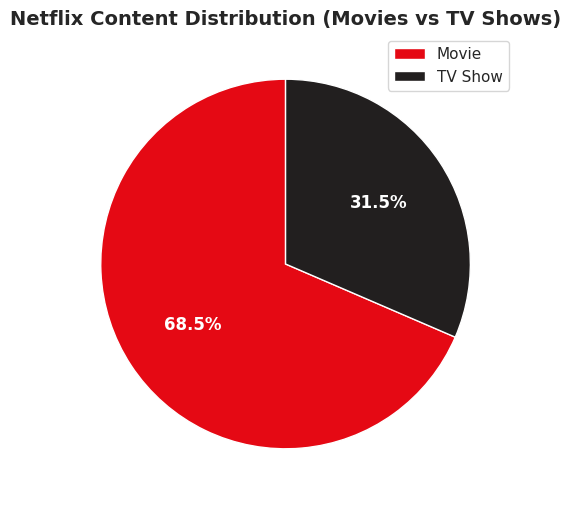

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean design style for our charts
sns.set_theme(style="whitegrid")

# 1. Create a Pie Chart for Movies vs TV Shows
plt.figure(figsize=(6, 6))
df['type'].value_counts().plot(
    kind='pie', legend=True,
    autopct='%1.1f%%',
    colors=['#E50914', '#221F1F'], # Netflix Red and Black
    startangle=90,
    textprops={'color':"white", 'weight':'bold'}
)
plt.title("Netflix Content Distribution (Movies vs TV Shows)", fontsize=14, weight='bold')
plt.ylabel("") # Removes the column name label from the side
plt.show()



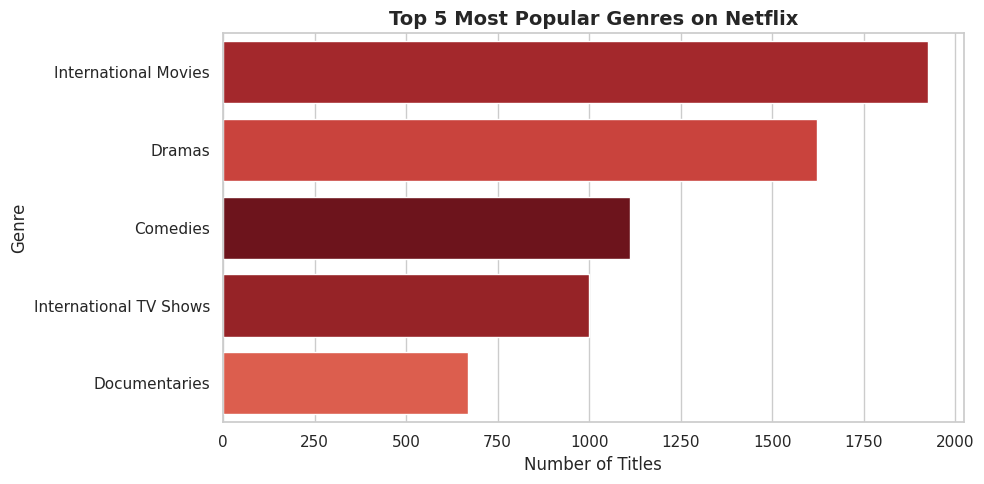

In [17]:
# 2. Create a Bar Chart for Top 5 Genres
plt.figure(figsize=(10, 5))
all_genres = df['listed_in'].str.split(', ').explode()
# Reset index to avoid 'cannot reindex on an axis with duplicate labels' error
all_genres = all_genres.reset_index(drop=True)
sns.countplot(
    y=all_genres,
    order=all_genres.value_counts().index[:5],
    palette="Reds_r", # Beautiful gradient of reds
    hue=all_genres, # Explicitly assign y to hue to resolve FutureWarning
    legend=False # Set legend to False as it's redundant here
)
plt.title("Top 5 Most Popular Genres on Netflix", fontsize=14, weight='bold')
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout() # Ensures labels don't get cut off
plt.show()